# PPMI Modality Analysis: Digital Mobile Telemetry & High-Frequency Sensors
**Notebook**: `eda_pca_digital_sensors.ipynb`  
**Modality Group**: `digital_sensors` (1 Scoped Analyzable Units)  
**Authoritative Scope**: `docs/important_modality_files.md`  
**Cohort Policy (Revision 4)**: Parkinson's disease (`PD`) and Healthy Controls (`HC`) Only  
**PCA Architecture**: Shared-space class-balanced component space fit on 1 deterministic record per participant  
**Governance Framework**: Codex Supervisory Review & `AGENTS.md` Task `EDA-PCA-001`  

---

## Modality Overview
High-frequency smartphone telemetry from the Roche PD Mobile Application substudy covering sustained phonation, rest and postural tremor, finger tapping, and gait balance.

### Scientific & Governance Invariants
1. **Target Cohort Restriction**: Analytical populations and PCA models are restricted exclusively to verified **Parkinson's disease (`PD`)** and **Healthy Controls (`HC`)**. Excluded classes (SWEDD, prodromal, genetic non-motor carriers) are filtered out prior to analysis. Cohort labels and disease staging fields never enter the PCA feature matrix.
2. **Participant-Level Shared-Space PCA**: For eligible participant-level tables, repeated visits are resolved to 1 record per participant (baseline preferred with stable tie-breaking and completeness checks). PCA and preprocessing (median imputation, scaling) are fit exclusively on a shared, deterministically class-balanced sample ($k = \min(N_{PD}, N_{HC})$, sampled via SHA-256 hash ranking) to reduce direct sample-count influence on component orientation, and all target participants are projected into this identical space.
3. **Comprehensive Committed EDA (Correction C1 / R4-02)**: Exact schemas with variable roles, missingness, duplicate rows, observation grain, numeric skewness, Tukey IQR and z-score outlier metrics, and categorical frequency summaries are visibly rendered in this notebook and committed directly to disk.
4. **Privacy-Safe Displays (Correction C3 / R4-05)**: Scree plots, loadings tables, and 2x2 side-by-side PD vs HC hexbin density score plots with cell suppression ($< 5$ observations masked) and outlier disclosures.
5. **Committed State Reproducibility (Correction C4 / R4-04)**: Loads directly from committed reports (`EDA/outputs/reports/`) using repository-relative POSIX paths with zero dependence on ignored cache.

In [1]:
import os
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 10

# Resolve repository root
repo_root = Path.cwd().resolve()
if (repo_root / "EDA" / "src").exists():
    sys.path.insert(0, str(repo_root / "EDA" / "src"))
elif (repo_root.parent / "EDA" / "src").exists():
    repo_root = repo_root.parent
    sys.path.insert(0, str(repo_root / "EDA" / "src"))

from ppmi_pipeline.reporting.privacy import PrivacyGuard

print(f"Environment initialized. Modality: 'digital_sensors', Dynamic repository root: ppmi")

Environment initialized. Modality: 'digital_sensors', Dynamic repository root: ppmi


## 1. Scoped Analyzable Units in Digital Mobile Telemetry & High-Frequency Sensors
The authoritative catalog assigns exactly **1 analyzable unit(s)** to this modality domain.

In [2]:
manifest_path = repo_root / "EDA" / "outputs" / "reports" / "priority_eda_pca_manifest.json"
with open(manifest_path, "r", encoding="utf-8") as f:
    manifest_data = json.load(f)

mod_units = [u for u in manifest_data["units"] if u.get("modality_group") == 'digital_sensors']

inv_rows = []
for unit_entry in mod_units:
    sheet_suffix = (" -> [" + str(unit_entry.get("sheet_name")) + "]") if unit_entry.get("sheet_name") else ""
    pca_stat_str = ("COMPLETED (" + str(unit_entry.get("pca_included_features_count", 0)) + " feats)") if unit_entry.get("pca_status") == "COMPLETED" else str(unit_entry.get("pca_skip_reason"))
    inv_rows.append({
        "Unit Slug": unit_entry["unit_slug"],
        "Filename / Sheet": str(unit_entry.get("declared_filename")) + sheet_suffix,
        "Physical Exists": "Yes" if unit_entry.get("physical_exists") else "No (Absent)",
        "EDA Status": unit_entry.get("eda_status"),
        "PCA Status": unit_entry.get("pca_status"),
        "PCA Reason / Features": pca_stat_str
    })

inv_df = pd.DataFrame(inv_rows)
display(inv_df)
print(f"Total units cataloged: {len(inv_df)} | EDA Completed: {(inv_df['EDA Status'] == 'COMPLETED').sum()} | PCA Completed: {(inv_df['PCA Status'] == 'COMPLETED').sum()}")

,Unit Slug,Filename / Sheet,Physical Exists,EDA Status,PCA Status,PCA Reason / Features
0,digital_Sensor_Roche_PD_Monitoring_App_v2_data...,Roche_PD_Monitoring_App_v2_data_09Nov2026.csv,Yes,COMPLETED,SKIPPED,Inadequate initial participant count for multi...


Total units cataloged: 1 | EDA Completed: 1 | PCA Completed: 0


---
## 2.1. Unit: `Roche_PD_Monitoring_App_v2_data_09Nov2026.csv` 
- **Unit Slug**: `digital_Sensor_Roche_PD_Monitoring_App_v2_data_09Nov2026_csv`
- **Source Path**: `digital_Sensor/Roche_PD_Monitoring_App_v2_data_09Nov2026.csv`
- **Committed Unit Artifact**: [`digital_Sensor_Roche_PD_Monitoring_App_v2_data_09Nov2026_csv.json`](../EDA/outputs/reports/units/digital_Sensor_Roche_PD_Monitoring_App_v2_data_09Nov2026_csv.json)
- **Declared Observation Grain**: `(PATNO, TIMESTAMP, TEST_TYPE)`
- **Selection Tier**: `Primary EDA` | **Role**: `High-frequency smartphone telemetry from the Roche PD Mobile Application monitoring substudy. Captures daily active test batteries: <br>• **Sustained Phonation**: Acoustic stability, jitter, shimmer, voice tremor.<br>• **Rest & Postural Tremor**: 3-axis accelerometer and gyroscope power spectrum frequencies.<br>• **Finger Tapping**: Bilateral tapping speed, cadence, and motor fatigue.<br>• **Balance & Turn Tests**: U-turn stability, gait symmetry, and sway velocity.<br>• **Cognitive Active Tests**: Symbol-digit substitution and daily symptom surveys.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `SKIPPED`

UNIT ANALYSIS: digital_Sensor/Roche_PD_Monitoring_App_v2_data_09Nov2026.csv
EDA Status: COMPLETED | PCA Status: SKIPPED
Dimensions: 60,373 analyzed rows x 23 columns
Observation Grain: Multiple repeated observations per participant (PATNO)
Candidate Primary Keys: []

Target Cohort Filtering Denominators:
  - Initial Rows: 108,901 (32 participants)
  - PD Retained:  55,406 rows (19 participants)
  - HC Retained:  4,967 rows (1 participants)
  - Non-Target Excluded: 48,528 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  0 rows

Exact Variable Schema & Storage Types (23 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,STUDYID,object,0,0.0%,1,Identifier
1,PATNO,int64,0,0.0%,20,Identifier
2,QRSCATID,object,0,0.0%,21,Identifier
3,QRSSCAT,object,"48,248",79.9%,7,Categorical / Text
4,QRSSTAT,float64,"60,373",100.0%,0,Analytical Numeric Measurement
5,QRSREAS,float64,"60,373",100.0%,0,Analytical Numeric Measurement
6,QRSCLMD,object,0,0.0%,3,Categorical / Text
7,QRSIVQFL,float64,"60,373",100.0%,0,Analytical Numeric Measurement
8,QRSIVQRS,float64,"60,373",100.0%,0,Analytical Numeric Measurement
9,QRSTSTID,object,0,0.0%,120,Identifier



Variable Role Distribution Summary:


,Count
variable_role,
Categorical / Text,6
Date / Timestamp / Visit,6
Analytical Numeric Measurement,5
Identifier,4
Demographic / Covariate,1
Cohort / Stratification Label,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 397,990 / 1,388,579 (28.66%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (8 total, top 8):


,name,missing_count,missing_percent,variable_role
4,QRSSTAT,"60,373",100.0%,Analytical Numeric Measurement
5,QRSREAS,"60,373",100.0%,Analytical Numeric Measurement
7,QRSIVQFL,"60,373",100.0%,Analytical Numeric Measurement
8,QRSIVQRS,"60,373",100.0%,Analytical Numeric Measurement
3,QRSSCAT,"48,248",79.9%,Categorical / Text
11,QRSLAT,"40,177",66.5%,Categorical / Text
20,QRSORESU,"38,703",64.1%,Categorical / Text
19,QRSRESC,"29,370",48.6%,Categorical / Text


... (4 outputs left out)

  * Feature: QRSLAT (Distinct Categories: 2)


,category,row_count
0,RIGHT,"10,121"
1,LEFT,"10,075"



Numeric Summaries & Outlier Diagnostics (2 continuous/discrete features):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,QRSRESN,10.093,29.56,-58.872,1.000,369.186,3.929,Strongly skewed (positive),"6,636","2,417"
1,Age,64.233,11.43,43.058,65.043,80.553,-0.464,Approximately symmetric,0,0


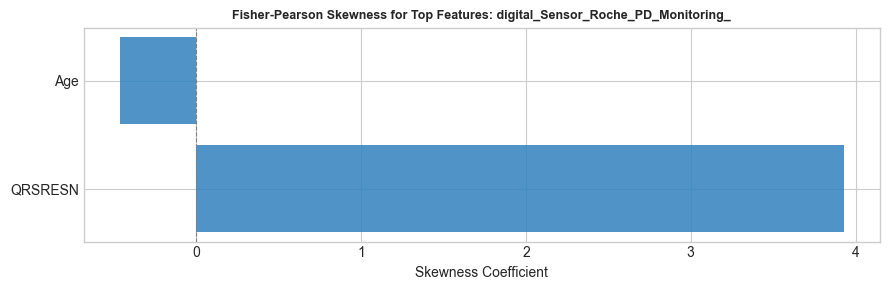

In [3]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "digital_Sensor_Roche_PD_Monitoring_App_v2_data_09Nov2026_csv.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: digital_Sensor/Roche_PD_Monitoring_App_v2_data_09Nov2026.csv")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to digital_Sensor_Roche_PD_Monitoring_App_v2_data_09Nov2026_csv.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in digital_Sensor_Roche_PD_Monitoring_App_v2_data_09Nov2026_csv.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: digital_Sensor_Roche_PD_Monitoring_", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Deterministic Skip
- **Status**: `SKIPPED`
- **Deterministic Skip Reason**: `Inadequate initial participant count for multivariate PCA (< 10 participants in target cohort)`
- **Methodological Justification**: This dataset does not meet the scientific prerequisites for multivariate PCA (e.g. lacks $\ge 2$ continuous analytical measurements, is an unpivoted single-measurement log, represents cell repository inventory, or lacks adequate two-class participant coverage).

In [4]:
pca_res = unit_data.get("pca_results") or {}
skip_reason = pca_res.get("skip_reason") or unit_data.get("pca_skip_reason")
print(f"PCA Skip Reason: {skip_reason}")
print(f"Features Evaluated: {pca_res.get('feature_count', 0)} included, {pca_res.get('excluded_features_count', 0)} excluded")
if pca_res.get("excluded_features"):
    ex_df = pd.DataFrame(pca_res["excluded_features"][:10])
    print("\nExcluded Variables Sample:")
    display(ex_df)

PCA Skip Reason: Inadequate initial participant count for multivariate PCA (< 10 participants in target cohort)
Features Evaluated: 0 included, 0 excluded


---
## 3. Modality Synthesis & Scientific Limitations

### Evidence-Bounded Findings
- **Data Coverage**: Analysis covered all 1 scoped analyzable unit(s) belonging to `Digital Mobile Telemetry & High-Frequency Sensors`.
- **Shared Coordinate Space**: All participant-level PCAs were estimated in a deterministically balanced coordinate space combining Parkinson's disease and healthy control cohorts, which reduces direct sample-count influence on component orientation.
- **Variance Patterns**: Scree and loading structures demonstrate dominant sources of numeric variance within the retained continuous feature space for this modality.

### Methodological Limitations
1. **Unadjusted Covariates**: PCA projections represent unadjusted variance; age, sex, and disease duration effects are not regressed out.
2. **Missingness Imputation**: Median imputation fitted exclusively on the class-balanced training sample was applied to replace missing values in retained features (features with > 40% missingness excluded), preserving sample size rather than performing complete-case deletion.
3. **No Causal / Diagnostic Claims**: PCA scores reflect descriptive data geometry and must not be interpreted as validated diagnostic classifiers or clinical progression endpoints without formal hypothesis testing.